# Unsupervised learning: clustering, nearest neighbours and PCA

*Data Science and AI, Module 6. Slides: `Module_6.pdf`.*

Keep the slides open on the right. Every heading below carries the slide
numbers it goes with, so the two stay in step.

Until now every dataset came with an answer column: tomorrow's temperature,
wet or dry. This module asks what we can learn when there is **no answer
column at all**.

**How each section works.** A question comes first. Make a guess out loud or
in the chat before the cell runs. Then run it and compare.

**Two kinds of data.**

- Small **made-up** examples, always labelled as made up, small enough to
  check by hand.
- One **real** dataset: the chemical analysis of wines from three growers in
  the same region of Italy. It comes with scikit-learn, so there is nothing to
  download, and it works the same on Windows, Mac and Colab.

**The wine story.** For most of the notebook we pretend the grower column was
lost. Clustering has to find groups from the measurements alone. Only at the
end (slide 32) do we bring the grower back, to check how well it did.

The notebook comes in four parts. Each part starts by loading everything it
needs, so you can restart the kernel between parts.

*Wine data: the UCI Wine recognition dataset (Forina et al.), as bundled with
scikit-learn as `load_wine`.*

# Part 1: slides 1-21

Clustering, and the K-means method.

Run this cell first. It loads the wine data and defines `show_groups`, a small
plotting helper used all the way through. You do not need to read the helper.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_wine

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# Real data that ships with scikit-learn: a chemical analysis of wines
# from three growers in the same region of Italy.
wine_data = load_wine(as_frame=True)
wine = wine_data.data          # the measurements: one row per wine
grower = wine_data.target      # which grower made each wine: 0, 1 or 2

print("wines:", len(wine), "| measurements per wine:", len(wine.columns))


def show_groups(points, groups, title, xlabel="x (made up)", ylabel="y (made up)"):
    """Scatter plot of 2-D points, one colour per group. Run this and move on."""
    plt.figure(figsize=(5, 4))
    plt.scatter(points[:, 0], points[:, 1], c=groups, cmap="viridis", s=12)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

## Slides 1-4: what changes when there is no answer column?

In Modules 4 and 5 every row had **features** $X_1, X_2, \dots, X_n$ and a
**response** $y$. The model learnt to predict $y$ from the features. That is
**supervised** learning: the answer column supervises the learning.

In **unsupervised** learning we only have the features. There is no $y$, so
there is nothing to predict and no right answer to score against. The job
becomes finding structure in the features themselves.

*Real-life example.* A supermarket has years of loyalty-card baskets, but
nobody has written "type of shopper" next to each customer. Clustering can
suggest groups of customers who shop alike. A person then decides whether the
groups mean anything.

Here are the wine features: the only thing clustering will be allowed to see.

In [ ]:
display(wine.head())

And here is the column we are putting aside until slide 32.

**Before running:** do you expect the three growers to have made roughly the
same number of these wines?

In [ ]:
# How many wines came from each grower.
print(grower.value_counts().sort_index())

### How is clustering different from classification?

**In one line:** classification learns *known* groups from labelled examples
and can be checked against the right answer. Clustering *finds* groups in
unlabelled data, and a person has to judge whether they mean anything.

| | Classification (supervised) | Clustering (unsupervised) |
|---|---|---|
| the data | features **and** a label column, $y$ | features only, no $y$ |
| the goal | predict the label of a new row | find groups among the rows |
| the groups | fixed in advance, with names ("wet", "dry") | discovered; numbered 0, 1, 2, not named |
| is it right? | checkable: compare predictions with the true labels on test data (accuracy, precision, recall) | no single score; judge by usefulness, or compare with labels if you happen to have some (slide 32) |
| how many groups | set by the labels | you choose it (K in K-means) or the method decides (DBSCAN) |
| example methods | logistic regression, SVM | K-means, DBSCAN, hierarchical clustering |

**The wine data, both ways.**

- *Classification:* "Here are some wines **with** their grower. Learn from
  them, then tell me the grower of these new wines." We can count how many it
  gets right, because we know the true answers. Part 3 does this with K-NN.
- *Clustering:* "Here are the wines and **no** growers. Are there natural
  groups?" K-means can find three groups, but it does not know they are
  growers; its "cluster 0" means nothing until a person looks. Slide 32 brings
  the hidden grower column back to check.

*Everyday version.* Supervised: a teacher hands you photos labelled "cat" or
"dog", and you learn to label new ones. Unsupervised: someone tips a box of
mixed buttons onto a table and you sort them into piles by size and colour.
Nobody told you the piles, and someone else might sort them differently,
which is slide 6's point that unsupervised learning is more subjective.


## Slides 5-6: what is unsupervised learning for?

Slide 5 gives two jobs:

- **a good picture of the data.** With 13 measurements per wine we cannot draw
  a scatter plot. Part 4 (PCA) squeezes them down to two so we can.
- **finding subgroups.** That is clustering, the rest of Parts 1 and 2.

Slide 6 makes two points.

- **It is more subjective.** With no answer column there is no single score
  that says "this grouping is right". Two analysts can reasonably disagree.
- **Unlabelled data is cheap; labels are expensive.** A lab instrument can
  record thousands of samples a day. Deciding whether each of a thousand movie
  reviews is favourable needs a person to read every one.

## Slides 7-8: what counts as a cluster?

A **cluster** is a group of objects that are more alike than objects in other
groups. The deck stresses that clustering is a task, not one algorithm:
methods differ in what "alike" means and how they search for groups.

Slide 8 lists three ideas of what makes a cluster:

- **distance**: members are close to each other, or to a centre (K-means)
- **density**: members sit in a crowded area of the space (DBSCAN, Part 2)
- **intervals or statistical distributions**: members fall in the same range,
  or look like draws from the same distribution. The deck does not take this
  one further.

Most of this module measures "close" with ordinary straight-line distance.
For two points $(x_1, y_1)$ and $(x_2, y_2)$ it is Pythagoras:

$$d = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}$$

With more than two measurements, add one squared difference per measurement
under the square root. Slide 39 writes the general version.

## Slides 9-11: three ways to find groups

- **Slide 9, distance from centre points.** Each point joins its nearest
  centre. This is K-means, from slide 13.
- **Slide 10, density.** Crowded areas become clusters and sparse gaps
  separate them. This is DBSCAN, from slide 22.
- **Slide 11, hierarchical.** Build a family tree of the points.

Hierarchical clustering can work **bottom-up**: start with every point on its
own, then keep merging the two closest groups until only one is left. (The
**top-down** version starts with one big group and keeps splitting it.) The
record of the merges is drawn as a **dendrogram**.

Here are six made-up points, named like the ones on slide 11.

In [ ]:
# Made-up: six points, named like the ones on slide 11.
names = ["A", "B", "C", "D", "E", "F"]
six = np.array([[1, 2], [1.5, 3], [5, 2.2], [7, 4], [7, 1], [8, 2]])

plt.figure(figsize=(5, 4))
plt.scatter(six[:, 0], six[:, 1])
for name, point in zip(names, six):
    plt.annotate(name, point, xytext=(5, 5), textcoords="offset points")
plt.xlabel("x (made up)")
plt.ylabel("y (made up)")
plt.title("Six made-up points")
plt.show()

**Before running:** bottom-up merging joins the closest pair first. Which pair
will that be? Which pair comes second?

The table below gives the distance between every pair of points.

In [ ]:
# Distance between every pair of points (Pythagoras), laid out as a table.
distances = pd.DataFrame(index=names, columns=names, dtype=float)
for i in range(len(six)):
    for j in range(len(six)):
        gap = six[i] - six[j]
        distances.iloc[i, j] = np.sqrt(gap[0] ** 2 + gap[1] ** 2)

distances.round(2)

The diagonal is zero: every point is zero distance from itself. The smallest
number off the diagonal is the first merge.

After a merge we need the distance from a **group** to another point or
group. The simplest rule is **single linkage**: use the gap between the two
closest members. (Other rules exist, such as the average gap; scipy offers
several.)

Now scipy does the merging and draws the tree. The height of each join is the
distance at which those two groups merged. Cutting the tree with a horizontal
line, like the dashed line on slide 11, leaves one group for every branch the
line crosses.

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# "single": the distance between two groups is the gap between their closest members.
merges = linkage(six, method="single")

plt.figure(figsize=(5, 4))
dendrogram(merges, labels=names, color_threshold=0)   # one colour: colours here would suggest groups
plt.ylabel("distance at which the groups merge")
plt.title("Dendrogram of the six made-up points")
plt.show()

# Cut the tree so that three groups remain.
groups = fcluster(merges, t=3, criterion="maxclust")
for name, group in zip(names, groups):
    print(name, "is in group", group)

Check the first two joins against the table: their heights are the two
smallest distances in it. Cutting into three groups gives the same answer as
the colours on slide 11.

## Slide 12: what makes a clustering good?

A good clustering has

- **high similarity inside each cluster**: members close together
- **low similarity between clusters**: clusters far apart

Slide 12 also warns that clustering **is not automatic**. You try something,
look at the result, change the preparation of the data or the settings, and
try again. This notebook shows each of those levers:

- scaling the data (slides 20 and 29)
- the neighbourhood size for DBSCAN (slide 23)
- the number of clusters for K-means (slide 29)

## Slides 13-16: how does K-means work?

K-means splits the data into $K$ groups. Each group has a **centre**, also
called a **centroid**: the mean of its members, which is where the "means"
in K-means comes from.

Slide 15 gives the target. With groups $S_1, \dots, S_k$ and their means
$\mu_1, \dots, \mu_k$, K-means looks for the grouping that makes this total as
small as possible:

$$\sum_{i=1}^{k} \; \sum_{x \in S_i} \lVert x - \mu_i \rVert^2$$

In words: for each group, take every member's distance to the group's centre,
square it, and add them up. Then add the totals of all the groups.
scikit-learn calls this total the **inertia**.

Slide 16's recipe, in plain words:

1. Choose $K$, the number of groups.
2. Choose $K$ starting centres.
3. Work out the distance from every point to every centre.
4. Give each point to its nearest centre.
5. Move each centre to the mean of the points it was given.
6. Repeat steps 3 to 5 until the centres stop moving.

This loop is known as **Lloyd's algorithm** (slide 14). Once it stops, each
centre owns the region of space that is closer to it than to any other centre;
those regions are the cells of a **Voronoi diagram**.

Step 2 says "randomly" on slide 16. scikit-learn's default is smarter
(`k-means++`, slide 29). Below we choose the starting centres ourselves so
that every step can be followed by hand.

Now the same six points through scikit-learn, starting from the same two
centres. We also compute slide 15's total by hand and compare it with
scikit-learn's `inertia_`. The `assert` lines stop the notebook with an error
if the two disagree, so if the cell runs, they agree.

In [ ]:
# K-means in three steps: scale, cluster, compare.
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Put all 13 measurements on the same scale (slide 29 explains why).
wine_scaled = StandardScaler().fit_transform(wine)

# 2. Ask K-means for 3 groups. It only sees the measurements, never the grower.
kmeans = KMeans(n_clusters=3, random_state=0)
wine_groups = kmeans.fit_predict(wine_scaled)

# 3. Peek: how do the groups K-means found line up with the real growers?
pd.crosstab(wine_groups, grower, rownames=["K-means group"], colnames=["grower"])

In [ ]:
# K-means in three steps: scale, cluster, compare.
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Put all 13 measurements on the same scale (slide 29 explains why).
wine_scaled = StandardScaler().fit_transform(wine)

# 2. Ask K-means for 3 groups. It only sees the measurements, never the grower.
kmeans = KMeans(n_clusters=3, random_state=0)
wine_groups = kmeans.fit_predict(wine_scaled)

# 3. Peek: how do the groups K-means found line up with the real growers?
pd.crosstab(wine_groups, grower, rownames=["K-means group"], colnames=["grower"])

In [ ]:
import seaborn as sns
plt.figure(figsize=(6, 5))
# Create the crosstab
ct = pd.crosstab(wine_groups, grower)

# Plot as a heatmap
sns.heatmap(ct, annot=True, cmap="Blues", fmt="d", cbar=False)
plt.title("K-Means Groups vs. Real Growers")
plt.xlabel("Real Grower")
plt.ylabel("K-Means Group")
plt.show()

In [ ]:
import pandas as pd

test_group = ["A", "A", "A", "B", "B", "B", "A"]
outcome    = ["Pass", "Pass", "Fail", "Fail", "Fail", "Pass", "Pass"]

pd.crosstab(test_group, outcome, rownames=["Test Group"], colnames=["Outcome"]) #[["Pass", "Fail"]]

## Slide 17: when does K-means go wrong?

Slide 17's four pictures come from a scikit-learn example. We rebuild each
case with `make_blobs`, scikit-learn's maker of round clouds of points. It
also tells us which cloud each point came from, so we can see when K-means
gets it wrong. Real unlabelled data would not tell us that.

K-means works best when:

- you asked for the right number of groups
- the groups are round, not stretched (**isotropic**: the same spread in every
  direction)
- the groups have roughly the same spread as each other
- no single group is so big that it dominates the total

`random_state=0` fixes the random numbers, so everyone gets the same picture.

**Case 1: the wrong number of groups.** Three clouds, but we ask for two.

**Before running:** what will K-means do with the third cloud?

For the next three cases we ask for the right number of groups, and we
compare two totals using slide 15's formula:

- the total for **K-means' grouping**
- the total for **the true clouds**

**Before running each one:** which total do you expect to be smaller?

**Case 2: stretched groups.** Three clouds one above the other, then every
point's x value multiplied by 6, so each cloud becomes a long flat band.

**Case 3: unequal spread.** Three clouds side by side: a medium one, a wide
one and a tight one.

**Case 4: very different sizes.** Three clouds side by side: one big, one
medium, one tiny.

In cases 2, 3 and 4 the wrong-looking answer has the **smaller** total. So
K-means did what it is built to do: it found a lower slide 15 total than the
true groups have. The trouble is that a low total is not the same as finding the groups a person
would see.

Case 4 needs care. Nothing in the theory says K-means needs equal-sized
groups. What happens is that the big cloud holds most of the points, so it
contributes most of the total. Splitting it in two lowers the total more than
giving the tiny cloud a centre of its own. The crosstab shows that split.

The totals differ, so some starts got stuck. This is why scikit-learn has
`n_init` (slide 29): run several starts and keep the one with the smallest
total.

**2. One outlier can grab a centre.** Back to the six corner points, plus one
point far away at (30, 30), and we ask for two groups.

**Before running:** where will the two centres end up?

The lone outlier got a centre all to itself, and the two real corners were
merged into one group. A single unusual point decided the whole answer.

**3. Distance weighs measurements by their size.** Slide 20 says Euclidean
distance "might weigh underlying factors incorrectly". The wine data shows it
clearly.

**Before running:** of the 13 wine measurements, which do you expect to have
the biggest range of values?

## Slide 21: try K-means in the browser

Naftali Harris's interactive page:
https://www.naftaliharris.com/blog/visualizing-k-means-clustering/

It asks how to pick the starting centres: **I'll Choose**, **Randomly** or
**Farthest Point**. Then press its two steps in turn: **Reassign Points**
(slide 16's step 4) and **Update Centroids** (step 5). The shaded areas are the
Voronoi cells from slide 14.

Try "I'll Choose" and put all the starting centres in one corner, then watch
them move. Then try "Randomly" a few times on the same data and see whether
the final groups always match.

In [ ]:
# load and clean
import pandas as pd

penguins = pd.read_csv("../../../data/penguins_size.csv")
print(penguins.shape)          # (344, 7)

# Two birds have no measurements at all, so drop them.
measurements = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins = penguins.dropna(subset=measurements)
print(penguins.shape)          # (342, 7)

# Hide the answer: K-means only gets the four measurements.
species = penguins["species"]
penguin_data = penguins[measurements]
print(penguin_data.describe().round(1))
display(penguin_data)

In [ ]:
#scale, cluster, compare
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Put all 4 measurements on the same scale.
penguin_scaled = StandardScaler().fit_transform(penguin_data)

# 2. Ask K-means for 3 groups. It never sees the species.
penguin_kmeans = KMeans(n_clusters=3, random_state=0)
penguin_groups = penguin_kmeans.fit_predict(penguin_scaled)

# 3. Compare the groups with the real species.
pd.crosstab(penguin_groups, species, rownames=["group"], colnames=["species"])

In [ ]:
# Same K-means on the raw numbers. body_mass_g is in the thousands,
# so it swamps the other three columns.
from sklearn.metrics import v_measure_score

raw_groups = KMeans(n_clusters=3, random_state=0).fit_predict(penguin_data)

print("V-measure, raw:", round(v_measure_score(species, raw_groups), 3))   # 0.405
pd.crosstab(raw_groups, species, rownames=["group"], colnames=["species"])

# Part 2: slides 22-32

DBSCAN, categories, K-means in scikit-learn, and how to judge a clustering.

Run this cell first. It reloads the wine data and the plotting helper.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_wine

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# Real data that ships with scikit-learn: a chemical analysis of wines
# from three growers in the same region of Italy.
wine_data = load_wine(as_frame=True)
wine = wine_data.data          # the measurements: one row per wine
grower = wine_data.target      # which grower made each wine: 0, 1 or 2

print("wines:", len(wine), "| measurements per wine:", len(wine.columns))


def show_groups(points, groups, title, xlabel="x (made up)", ylabel="y (made up)"):
    """Scatter plot of 2-D points, one colour per group. Run this and move on."""
    plt.figure(figsize=(5, 4))
    plt.scatter(points[:, 0], points[:, 1], c=groups, cmap="viridis", s=12)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

## Slides 22-23: how does DBSCAN find groups?

DBSCAN stands for Density-Based Spatial Clustering of Applications with
Noise. It has two settings:

- **eps** (epsilon): the radius of a point's neighbourhood
- **min_samples**: scikit-learn's name for the deck's *minPoints*. It counts
  the point itself.

Every point ends up as one of three kinds:

- **core point**: at least `min_samples` points within `eps` of it, itself
  included
- **border point**: fewer than that, but within `eps` of a core point. It
  joins that core point's cluster.
- **noise**: neither of the above. scikit-learn labels it `-1`.

A cluster grows outwards from core points. Every neighbour of a core point
joins the cluster; if that neighbour is also a core point, its neighbours join
too, and so on until nothing new can be reached. Then DBSCAN starts a new
cluster from an unvisited core point.

Unlike K-means, you do not tell DBSCAN how many clusters to find.


In [ ]:
from sklearn.cluster import DBSCAN

# The six made-up points from slide 11.
names = ["A", "B", "C", "D", "E", "F"]
six = np.array([[1, 2], [1.5, 3], [5, 2.2], [7, 4], [7, 1], [8, 2]])

# Change these two and run again.
eps = 2
min_samples = 2

model = DBSCAN(eps=eps, min_samples=min_samples)
model.fit(six)
print("labels:", model.labels_)     # -1 means noise

plt.figure(figsize=(7, 4))
plt.scatter(six[:, 0], six[:, 1], s=200)
for i in range(len(six)):
    # Write the name and the label next to each point.
    plt.text(six[i, 0] + 0.2, six[i, 1] + 0.2, names[i] + ": " + str(model.labels_[i]), fontsize=14)

# Draw the eps circle around each core point.
for i in model.core_sample_indices_:
    circle = plt.Circle((six[i, 0], six[i, 1]), eps, fill=False, linestyle="--", color="grey")
    plt.gca().add_patch(circle)

plt.gca().set_aspect("equal")     # so the circles look round
plt.xlim(-1, 10)
plt.ylim(-1, 6)
plt.title("eps " + str(eps) + ", min_samples " + str(min_samples) + "   (-1 = noise)")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN

names = ["A", "B", "C", "D", "E", "F"]
six = np.array([[1, 2], [1.5, 3], [5, 2.2], [7, 4], [7, 1], [8, 2]])
eps = 2.3
min_samples = 2

# Each step: a title, the label of every point so far, and the point
# whose eps circle we are looking at. None = no label yet.
steps = [
    ("start: no labels",           [None, None, None, None, None, None], None),
    ("visit A: core, start 0",     [0,    None, None, None, None, None], 0),
    ("B is in A's circle: joins",  [0,    0,    None, None, None, None], 0),
    ("visit C: not core, skip",    [0,    0,    None, None, None, None], 2),
    ("visit D: core, start 1",     [0,    0,    None, 1,    None, None], 3),
    ("F is in D's circle: joins",  [0,    0,    None, 1,    None, 1   ], 3),
    ("E is in F's circle: joins",  [0,    0,    None, 1,    1,    1   ], 5),
    ("end: C never joined = noise", [0,   0,    -1,   1,    1,    1   ], None),
]

colours = {None: "lightgrey", -1: "white", 0: "C0", 1: "C1"}

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for step, ax in zip(steps, axes.flatten()):
    title, labels, circle_at = step
    for i in range(len(six)):
        ax.scatter(six[i, 0], six[i, 1], s=200, color=colours[labels[i]], edgecolors="black")
        ax.text(six[i, 0] + 0.3, six[i, 1] + 0.3, names[i], fontsize=12)
    if circle_at is not None:
        circle = plt.Circle(six[circle_at], eps, fill=False, linestyle="--", color="grey")
        ax.add_patch(circle)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-1, 10)
    ax.set_ylim(-1, 6)
plt.tight_layout()
plt.show()

# Check: our last step matches what scikit-learn gives.
model = DBSCAN(eps=eps, min_samples=min_samples).fit(six)
print("scikit-learn:", model.labels_)       # [ 0  0 -1  1  1  1]
print("our last step:", steps[-1][1])       # [0, 0, -1, 1, 1, 1]

In [ ]:
# choose eps
from sklearn.neighbors import NearestNeighbors

# 1. Choose min_samples. 5 is a common place to start.
min_samples = 5

# 2. For each penguin, find the distance to its 5th nearest neighbour
#    (the penguin itself counts as the 1st, as it does in DBSCAN).
neighbours = NearestNeighbors(n_neighbors=min_samples).fit(penguin_scaled)
distances, _ = neighbours.kneighbors(penguin_scaled)
fifth_distance = np.sort(distances[:, min_samples - 1])

# 3. Plot them smallest to largest. Where the curve bends sharply upwards,
#    points stop being in a crowd. That bend is a good eps.
plt.plot(fifth_distance)
plt.xlabel("penguins, sorted")
plt.ylabel("distance to 5th nearest neighbour")
plt.title("Choosing eps for the penguins")
plt.grid(True)
plt.show()

In [ ]:
# cluster, count, compare
from sklearn.cluster import DBSCAN

# 4. Run DBSCAN with the eps read off the bend. It never sees the species.
penguin_dbscan = DBSCAN(eps=0.7, min_samples=min_samples)
dbscan_groups = penguin_dbscan.fit_predict(penguin_scaled)
"""
Same as:
penguin_dbscan = DBSCAN(eps=0.5, min_samples=min_samples)
penguin_dbscan.fit(penguin_scaled)
dbscan_groups = penguin_dbscan.labels_
"""

# 5. Count what it found. We did not tell it how many groups to make.
clusters = 0
for label in np.unique(dbscan_groups):
    if label != -1:              # -1 is noise, not a cluster
        clusters += 1
print("clusters found:", clusters)                       # 2
print("noise points:", (dbscan_groups == -1).sum())      # 16

# 6. Compare the groups with the real species. Group -1 is the noise.
pd.crosstab(dbscan_groups, species, rownames=["group"], colnames=["species"])

What the result shows: DBSCAN finds 2 groups, not 3. Gentoo forms its own group, but Adelie and Chinstrap end up together, because their measurements overlap and no empty gap separates them. DBSCAN only splits groups where there is a sparse gap, while K-means splits wherever you tell it to. DBSCAN also sets aside 16 birds as noise, which K-means can't do.

Possible follow-up: with eps=0.5 DBSCAN finds 4 groups and 69 noise points, and Chinstrap splits in two. That shows the "not automatic" point from slide 12 on real data. I checked these numbers but didn't write a cell for them.

In [ ]:
# cluster, count, compare
from sklearn.cluster import DBSCAN

# 4. Run DBSCAN with the eps read off the bend. It never sees the species.
penguin_dbscan = DBSCAN(eps=0.5, min_samples=min_samples)
dbscan_groups = penguin_dbscan.fit_predict(penguin_scaled)

# 5. Count what it found. We did not tell it how many groups to make.
clusters = 0
for label in np.unique(dbscan_groups):
    if label != -1:              # -1 is noise, not a cluster
        clusters += 1
print("clusters found:", clusters)                       # 2
print("noise points:", (dbscan_groups == -1).sum())      # 16

# 6. Compare the groups with the real species. Group -1 is the noise.
pd.crosstab(dbscan_groups, species, rownames=["group"], colnames=["species"])

In [ ]:
# core, border and noise points
# Which penguins are core points? DBSCAN keeps a list of their row numbers.
is_core = np.zeros(len(dbscan_groups), dtype=bool)
is_core[penguin_dbscan.core_sample_indices_] = True
is_noise = dbscan_groups == -1
is_border = ~is_core & ~is_noise

# Draw on two of the four measurements we clustered on.
x = penguin_data["culmen_length_mm"]
y = penguin_data["culmen_depth_mm"]
colours = {0: "tab:orange", 1: "tab:blue"}

plt.figure(figsize=(7, 6))
for group in [0, 1]:
    core = is_core & (dbscan_groups == group)
    border = is_border & (dbscan_groups == group)
    plt.scatter(x[core], y[core], s=40, color=colours[group],
                label="group " + str(group) + ", core")
    plt.scatter(x[border], y[border], s=12, color=colours[group],
                label="group " + str(group) + ", border")
plt.scatter(x[is_noise], y[is_noise], s=40, facecolors="none",
            edgecolors="black", label="noise (-1)")

plt.xlabel("culmen length (mm)")
plt.ylabel("culmen depth (mm)")
plt.title("DBSCAN on the penguins (eps 0.7, min_samples 5)")
plt.legend()
plt.grid(True)
plt.show()
print("core:", is_core.sum(), "border:", is_border.sum(), "noise:", is_noise.sum())

In [ ]:
# core, border and noise points
# Which penguins are core points? DBSCAN keeps a list of their row numbers.
is_core = np.zeros(len(dbscan_groups), dtype=bool)
is_core[penguin_dbscan.core_sample_indices_] = True
is_noise = dbscan_groups == -1
is_border = ~is_core & ~is_noise

# Draw on two of the four measurements we clustered on.
x = penguin_data["culmen_length_mm"]
y = penguin_data["culmen_depth_mm"]

plt.figure(figsize=(7, 6))
for group in range(clusters):          # groups are numbered 0, 1, 2, ...
    core = is_core & (dbscan_groups == group)
    border = is_border & (dbscan_groups == group)
    plt.scatter(x[core], y[core], s=40, color="C" + str(group),
                label="group " + str(group) + ", core")
    plt.scatter(x[border], y[border], s=12, color="C" + str(group),
                label="group " + str(group) + ", border")
plt.scatter(x[is_noise], y[is_noise], s=40, facecolors="none",
            edgecolors="black", label="noise (-1)")

plt.xlabel("culmen length (mm)")
plt.ylabel("culmen depth (mm)")
plt.title("DBSCAN on the penguins (eps 0.5, min_samples 5)")
plt.legend()
plt.grid(True)
plt.show()
print("core:", is_core.sum(), "border:", is_border.sum(), "noise:", is_noise.sum())

Having few neighbours does not make a point noise. Being out of reach of
every core point does.


Too small, and the moons break into fragments with stray points left as
noise. Too big, and everything joins one cluster.

## Slide 24: try DBSCAN in the browser

https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/

Pick a dataset (try **Smiley Face** or **DBSCAN Rings**), then change epsilon
and minPoints and watch the clusters appear.

## Slide 25: Lab 6.1

Lab 6.1 practises K-means on scikit-learn's sample data.

## Slides 26-28: what about categories?

K-means needs a mean and a distance. A category such as a colour has neither.
The obvious trick, giving each category a number, quietly invents both.

**Before running:** if red = 1, green = 2 and blue = 3, is red closer to green
or to blue? And what is the "average" of red and blue?

In [ ]:
# Made-up: code three colours as numbers, then treat the numbers as distances.
colour_code = {"red": 1, "green": 2, "blue": 3}

print("distance red to green:", abs(colour_code["red"] - colour_code["green"]))
print("distance red to blue: ", abs(colour_code["red"] - colour_code["blue"]))
print("mean of red and blue: ", (colour_code["red"] + colour_code["blue"]) / 2)

The numbers say red is nearer green than blue, and that the average of red
and blue is green. Neither means anything: the order came from the order we
typed the colours in.

**Ordinal** variables (slide 27) are different. Low < medium < high really is
an order, so replacing them with 1, 2, 3 is reasonable. Equal steps are still
a choice, though: is the gap from school to college the same size as the gap
from college to university? That is a question about the subject, not about
the code.

In [ ]:
# Made-up: an ordinal column, replaced by numbers that keep its order.
risk = pd.Series(["low", "high", "medium", "low", "high"])
risk_order = {"low": 1, "medium": 2, "high": 3}
print(risk.map(risk_order).tolist())

**K-modes** (slide 28) clusters categories without inventing numbers.

- Instead of a distance it counts **mismatches**: the number of columns where
  two rows disagree. The fewer mismatches, the more alike.
- Instead of a mean, each cluster's centre is a **mode**: the most common
  value in each column.

Five made-up customers.

**Before running:** what does the most typical customer look like?

In [ ]:
# Made-up: five customers described only by categories.
customers = pd.DataFrame({
    "colour":  ["red", "red", "blue", "red", "blue"],
    "size":    ["small", "small", "large", "small", "large"],
    "payment": ["card", "cash", "card", "card", "card"],
})
display(customers)
# The mode: the most common value in each column.
mode = customers.mode().iloc[0]
print("most typical customer:", mode.tolist())      # ['red', 'small', 'card']

# Mismatches: compare every customer with the mode, count the differences.
customers["mismatches"] = (customers != mode).sum(axis=1)
customers

In [ ]:
#customers["colour"].mode()
customers.mode() #.iloc[0]

K-modes works like K-means with these two swaps: give each row to the mode it
has fewest mismatches with, then recompute each cluster's mode, and repeat.
There is one mode per cluster, playing the part of a centroid.

## Slide 29: K-means in scikit-learn

Slide 29's settings, in plain words:

| setting | what it does |
|---|---|
| `n_clusters` | how many groups ($K$) |
| `init` | how to choose the starting centres. The default, `"k-means++"`, picks the first centre at random and then favours points far from the centres already chosen. |
| `n_init` | how many separate runs from different starts. scikit-learn keeps the run with the smallest total. In this version the default is `"auto"`, which means 1 run with `k-means++`. |
| `max_iter` | the most rounds allowed in one run |
| `tol` | stop a run once the centres barely move between rounds |

First, the fix from slide 20. **Scaling** puts every measurement on the same
footing: subtract the column's mean, then divide by its standard deviation.

$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$

After scaling, every column has mean 0 and standard deviation 1, so a value of
2 means "two standard deviations above average" whatever the original units.
scikit-learn's `StandardScaler` does this.

In [ ]:
from sklearn.preprocessing import StandardScaler

wine_scaled = StandardScaler().fit_transform(wine)

# Check: every column now has mean 0 and standard deviation 1.
# abs() drops the minus sign that tiny rounding errors leave, like -0.000000.
print("column means:", np.abs(wine_scaled.mean(axis=0)).round(6))
print("column standard deviations:", wine_scaled.std(axis=0).round(6))

**How many clusters?** Slide 29 mentions the **elbow curve**. Run K-means for
$K$ = 1, 2, 3, ... and plot the total (inertia) each time. The best possible
total never rises as $K$ grows, since more centres means every point can be
nearer one. We
look for the bend, the point after which extra clusters stop helping much.

**Before running:** remember we are pretending not to know the grower. Where
do you expect the bend?

In [ ]:
k_values = range(1, 9)
totals = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(wine_scaled)
    totals.append(model.inertia_)
    print("K =", k, "-> total:", round(model.inertia_, 1))

plt.figure(figsize=(5, 4))
plt.plot(k_values, totals, marker="o")
plt.xlabel("number of clusters K")
plt.ylabel("total squared distance (inertia)")
plt.title("Elbow curve for the scaled wine data")
plt.show()

In [ ]:
k_values = range(1, 9)
totals = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(penguin_scaled)
    totals.append(model.inertia_)
    print("K =", k, "-> total:", round(model.inertia_, 1))

plt.figure(figsize=(5, 4))
plt.plot(k_values, totals, marker="o")
plt.xlabel("number of clusters K")
plt.ylabel("total squared distance (inertia)")
plt.title("Elbow curve for the scaled wine data")
plt.show()

The bend on real data is usually soft, not a sharp elbow. That is normal, and
it is why slide 29 also says to use domain knowledge and to experiment.

Here is the final model with every slide 29 setting written out.

In [ ]:
model = KMeans(
    n_clusters=3,        # how many groups
    init="k-means++",    # how to choose the starting centres (the default)
    n_init=10,           # 10 runs from different starts; keep the best
    max_iter=300,        # at most 300 rounds per run (the default)
    tol=0.0001,          # stop once the centres barely move (the default)
    random_state=0,      # same random starts every time, so the output repeats
)
wine_clusters = model.fit_predict(wine_scaled)

print("wines in each cluster:")
print(pd.Series(wine_clusters).value_counts().sort_index())

## Slides 30-31: Labs 6.1.1 and 6.2

Lab 6.1.1 applies scikit-learn's K-means to the Australian athletes data. Lab
6.2 explores the cases where K-means goes wrong, like the four on
slide 17.

## Slide 32: how do we judge a clustering?

There is no simple score. Slide 32 suggests two ways:

- check whether the clusters help with another task, such as a supervised one
- if you have **some labelled data**, compare the clusters with the labels

We have the grower, so we can do the second. A crosstab shows where each
cluster's wines really came from. The cluster numbers are arbitrary: cluster 0
does not have to match grower 0.

scikit-learn gives scores between 0 (bad) and 1 (perfect):

- **homogeneity**: does each cluster hold wines from only one grower?
- **completeness**: does each grower's wine land in only one cluster?
- **V-measure**: one number combining the two (their harmonic mean)

$$V = \frac{2 \times \text{homogeneity} \times \text{completeness}}{\text{homogeneity} + \text{completeness}}$$

*Real-life example.* Sorting laundry into baskets. Homogeneity asks whether
each basket holds one kind of item. Completeness asks whether all the socks
ended up in the same basket.

In [ ]:
from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score

print(pd.crosstab(wine_clusters, grower, rownames=["cluster"], colnames=["grower"]))
print()

homogeneity = homogeneity_score(grower, wine_clusters)
completeness = completeness_score(grower, wine_clusters)
v_measure = v_measure_score(grower, wine_clusters)
print("homogeneity: ", round(homogeneity, 3))
print("completeness:", round(completeness, 3))
print("V-measure:   ", round(v_measure, 3))

# Check the V-measure formula above against scikit-learn.
assert np.isclose(v_measure, 2 * homogeneity * completeness / (homogeneity + completeness))

Without ever seeing the grower, K-means put almost every wine with others from
the same grower.

Now the payoff for slide 20. The same K-means on the **raw**, unscaled data.

**Before running:** better, worse, or about the same?

In [ ]:
raw_clusters = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(wine)

print(pd.crosstab(raw_clusters, grower, rownames=["cluster"], colnames=["grower"]))
print()
print("homogeneity: ", round(homogeneity_score(grower, raw_clusters), 3))
print("completeness:", round(completeness_score(grower, raw_clusters), 3))
print("V-measure:   ", round(v_measure_score(grower, raw_clusters), 3))

Same data, same method, same settings. The only difference is one line of
scaling.

**Is it really all proline?** Run K-means on the proline column alone and
compare its groups with the unscaled run on all 13 measurements.

In [ ]:
proline_only = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(wine[["proline"]])
print(pd.crosstab(raw_clusters, proline_only,
                  rownames=["all 13, unscaled"], colnames=["proline only"]))

Each row has one non-zero cell: the two runs put every wine in the same group.
Without scaling, twelve of the thirteen
measurements made no difference to the groups.

# Part 3: slides 33-50

K-nearest neighbours (K-NN).

Run this cell first. It reloads the wine data and the plotting helper.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_wine

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# Real data that ships with scikit-learn: a chemical analysis of wines
# from three growers in the same region of Italy.
wine_data = load_wine(as_frame=True)
wine = wine_data.data          # the measurements: one row per wine
grower = wine_data.target      # which grower made each wine: 0, 1 or 2

print("wines:", len(wine), "| measurements per wine:", len(wine.columns))


def show_groups(points, groups, title, xlabel="x (made up)", ylabel="y (made up)"):
    """Scatter plot of 2-D points, one colour per group. Run this and move on."""
    plt.figure(figsize=(5, 4))
    plt.scatter(points[:, 0], points[:, 1], c=groups, cmap="viridis", s=12)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

## Slides 33-36: classify a point by asking its neighbours

One thing to be clear about first: **K-NN is supervised.** It needs labelled
examples, like the classifiers in Module 5. It sits in this module because it
runs on the same idea as clustering: distance.

Goethe's line on slide 34 is the whole method: *tell me who your neighbours
are, and I will tell you who you are.* To classify a new point:

1. find the $k$ labelled points nearest to it
2. take a **majority vote** of their labels

K-NN is called **lazy learning** (slide 36): there is no real training step.
"Learning" means storing the examples, and all the work happens when a
prediction is asked for. It is also called **instance-based**, because it
predicts from stored instances rather than from a fitted formula. The same idea
works for regression: average the neighbours' values instead of voting.

Made-up points like slide 35: class A and class B, and a new point "?" at
(0, 0).

In [ ]:
# Made-up labelled points, like the picture on slide 35.
labelled = pd.DataFrame({
    "x": [0.4, -2.0, -2.1, 1.6, -0.8, 1.5, -1.0, 0.9, 0.6],
    "y": [-0.5, -0.6, 1.0, -1.6, 1.1, -0.6, -2.0, 2.2, -2.8],
    "label": ["A", "A", "A", "A", "B", "B", "B", "B", "B"],
})

plt.figure(figsize=(5, 4))
for label, colour in [("A", "blue"), ("B", "orange")]:
    rows = labelled[labelled["label"] == label]
    plt.scatter(rows["x"], rows["y"], color=colour, label="class " + label)
plt.scatter([0], [0], color="black", marker="x", s=80, label="new point ?")
plt.xlabel("x (made up)")
plt.ylabel("y (made up)")
plt.legend()
plt.title("Which class is the new point?")
plt.show()

**Before running:** what does the vote say with $k$ = 1? With $k$ = 3? With
$k$ = 5?

In [ ]:
# Distance from the new point (0, 0) to every labelled point.
new_x, new_y = 0, 0
distances = []
for i in range(len(labelled)):
    gap_x = labelled["x"][i] - new_x
    gap_y = labelled["y"][i] - new_y
    distances.append(np.sqrt(gap_x ** 2 + gap_y ** 2))
labelled["distance"] = distances

nearest_first = labelled.sort_values("distance")
print(nearest_first.round(3))
print()

for k in [1, 3, 5]:
    votes = nearest_first.head(k)["label"].value_counts()
    print("k =", k, "| votes:", votes.to_dict(), "| prediction:", votes.idxmax())

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

new_point = pd.DataFrame({"x": [0], "y": [0]})

for k in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(labelled[["x", "y"]], labelled["label"])     # "learning" = storing the points
    print("k =", k, "| prediction:", knn.predict(new_point)[0], "| share of votes (A, B):", knn.predict_proba(new_point)[0])

In [ ]:
#labelled[["x", "y", "label"]]

The answer changes with $k$. A small $k$ trusts the single closest example; a
larger $k$ listens to more of the neighbourhood.

## Slides 37-38: learning, predicting, and the trade-off

- **Learning:** store the training examples.
- **Predicting:** find the $k$ stored examples nearest the new point and take
  the most common label.

Slide 37 says 3 or 5 are common choices for $k$; scikit-learn's default is 5
(slide 49). The best value depends on the data, so in practice you try
several.

The trade-off on slide 38:

- learning is instant and nothing has to be optimised
- predicting is slow on big data, because every prediction measures the
  distance to every stored example
- features that have nothing to do with the label still add to the distance
  and mislead it
- with many features, "nearest" stops meaning much (Part 4 shows why)

## Slide 39: two ways to measure "close"

**Euclidean distance** is Pythagoras with any number of measurements:

$$E(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$

**Cosine similarity** ignores size and compares direction only:

$$\text{similarity} = \cos(\theta) = \frac{A \cdot B}{\lVert A \rVert \, \lVert B \rVert}$$

The top is the **dot product** (multiply matching entries, then add); the
bottom multiplies the two lengths. It is 1 when two vectors point the same
way and 0 when they are at right angles. For counts like the baskets below it
never goes below 0, so 0 means they share nothing. It is a similarity, so bigger means
closer; scikit-learn's `"cosine"` distance is 1 minus it.

*Real-life example.* Three made-up shopping baskets counting (apples, bread,
milk). The big basket is the small one five times over. The other basket has a
different mix.

**Before running:** by Euclidean distance, is the small basket closer to the
big basket or to the other one? By cosine similarity?

In [ ]:
# Made-up baskets: counts of (apples, bread, milk).
small = np.array([1, 2, 0])
big = np.array([5, 10, 0])      # the small basket, five times over
other = np.array([2, 1, 3])     # a different mix


def euclidean(a, b):
    total = 0
    for i in range(len(a)):
        total += (a[i] - b[i]) ** 2
    return np.sqrt(total)


def cosine_similarity_by_hand(a, b):
    dot = 0
    for i in range(len(a)):
        dot += a[i] * b[i]
    return dot / (np.sqrt((a ** 2).sum()) * np.sqrt((b ** 2).sum()))


print("Euclidean, small to big:  ", round(euclidean(small, big), 3))
print("Euclidean, small to other:", round(euclidean(small, other), 3))
print("cosine, small to big:     ", round(cosine_similarity_by_hand(small, big), 3))
print("cosine, small to other:   ", round(cosine_similarity_by_hand(small, other), 3))

Euclidean distance says the small basket is more like the other basket,
because the big one is far away in raw counts. Cosine similarity says the
small and big baskets are the same kind of shopping in a different amount.
Which is right depends on the question: for "what kind of shopper?", direction
matters more than size.


## Slides 40-42: K-NN on the real wines

Slide 40's recipe, using the grower as the label this time:

1. split the wines into a training part and a test part
2. choose $k$
3. for each test wine, find the $k$ nearest training wines and take the vote

`stratify=grower` keeps the same mix of growers in both parts.

**Before running:** what share of the test wines will K-NN with $k$ = 5 get
right?

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Keep 30% of the wines aside as a test the model never learns from.
wine_train, wine_test, grower_train, grower_test = train_test_split(
    wine, grower, test_size=0.3, random_state=0, stratify=grower
)
print("training wines:", len(wine_train), "| test wines:", len(wine_test))

model = KNeighborsClassifier(n_neighbors=5)
model.fit(wine_train, grower_train)
print("accuracy on the test wines:", round(model.score(wine_test, grower_test), 3))

In [ ]:
 #Predict every test wine and compare with the truth
predictions = model.predict(wine_test)

compare = pd.DataFrame({
    "predicted grower": predictions,
    "real grower": grower_test.values,
})
print(compare.head(10))
print("right:", (predictions == grower_test.values).sum(), "of", len(grower_test))

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(wine_train)                       # learn means and spreads from training wines only
train_scaled = scaler.transform(wine_train)
test_scaled = scaler.transform(wine_test)

raw_model = KNeighborsClassifier(n_neighbors=5).fit(wine_train, grower_train)
scaled_model = KNeighborsClassifier(n_neighbors=5).fit(train_scaled, grower_train)
print("accuracy, raw measurements:   ", round(raw_model.score(wine_test, grower_test), 3))
print("accuracy, scaled measurements:", round(scaled_model.score(test_scaled, grower_test), 3))

## Slides 43-45: strengths, drawbacks and a demo

**Strengths (slide 43):** a simple method that is easy to explain, makes no
assumption about the shape of the boundary between classes (so it copes with
curved boundaries), and handles classification or regression.

**Drawbacks (slide 44):** it keeps all of the training data, so it needs a
lot of memory; predictions get slow as the data grows; and irrelevant features
mislead the distance.

**Demo (slide 45):** Stanford's interactive K-NN page,
http://vision.stanford.edu/teaching/cs231n-demos/knn/

Each coloured area shows the class a new point there would get. Try $K$ = 1,
then $K$ = 7, and watch the boundaries smooth out. Areas where the vote is a
tie are coloured white. **L1** and **L2** are two distance measures: L2 is the
Euclidean distance above, L1 adds up the gaps along each axis instead (like
walking city blocks).

## Slides 46-49: making K-NN better

**Weighted voting (slide 46).** Instead of one vote each, a neighbour's vote
counts $1 / \text{distance}$, so nearer neighbours count for more. In
scikit-learn this is `weights="distance"`.

Back to the made-up points. With $k$ = 5 the plain vote went to B.

**Before running:** with weighted votes, does the answer change?

In [ ]:
X = labelled[["x", "y"]]
y = labelled["label"]

plain = KNeighborsClassifier(n_neighbors=5, weights="uniform").fit(X, y)
weighted = KNeighborsClassifier(n_neighbors=5, weights="distance").fit(X, y)
print("plain vote:   ", plain.predict(pd.DataFrame({"x": [0], "y": [0]})))
print("weighted vote:", weighted.predict(pd.DataFrame({"x": [0], "y": [0]})))


**Reduce dimensions (slide 48).** Fewer, better features make distance more
meaningful. Part 4 does this with PCA and tries K-NN again.

**Faster searching (slide 48).** A **k-d tree** stores the training points so
that a search can skip whole regions that are too far away to matter. It
finds exactly the same neighbours as checking every point; it is built to find
them faster on large data with few features. Locality Sensitive Hashing (LSH)
is a different technique for many features, which trades a little accuracy
for speed.

**Before running:** will the k-d tree and the check-every-point search
(`"brute"`) ever disagree on these test wines?

In [ ]:
tree_model = KNeighborsClassifier(n_neighbors=5, algorithm="kd_tree").fit(train_scaled, grower_train)
brute_model = KNeighborsClassifier(n_neighbors=5, algorithm="brute").fit(train_scaled, grower_train)

tree_predictions = tree_model.predict(test_scaled)
brute_predictions = brute_model.predict(test_scaled)
print("test wines where the two disagree:", (tree_predictions != brute_predictions).sum())

**Slide 49: K-NN in scikit-learn.** The settings, with their defaults:

| setting | default | what it does |
|---|---|---|
| `n_neighbors` | 5 | $k$, the number of neighbours that vote |
| `weights` | `"uniform"` | `"uniform"`: one vote each. `"distance"`: votes weighted by 1/distance. |
| `algorithm` | `"auto"` | how to search: `"ball_tree"`, `"kd_tree"`, `"brute"`, or `"auto"` to let scikit-learn choose |

## Slide 50: Lab 6.3

Lab 6.3 practises K-NN on scikit-learn's sample data.

# Part 4: slides 51-68

Principal component analysis (PCA), and the appendix.

Run this cell first. It reloads the wine data and the plotting helper.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_wine

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# Real data that ships with scikit-learn: a chemical analysis of wines
# from three growers in the same region of Italy.
wine_data = load_wine(as_frame=True)
wine = wine_data.data          # the measurements: one row per wine
grower = wine_data.target      # which grower made each wine: 0, 1 or 2

print("wines:", len(wine), "| measurements per wine:", len(wine.columns))


def show_groups(points, groups, title, xlabel="x (made up)", ylabel="y (made up)"):
    """Scatter plot of 2-D points, one colour per group. Run this and move on."""
    plt.figure(figsize=(5, 4))
    plt.scatter(points[:, 0], points[:, 1], c=groups, cmap="viridis", s=12)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

numpy 2.3.5 | pandas 2.3.3 | scikit-learn 1.9.0
wines: 178 | measurements per wine: 13


## Slides 51-53: why too many features hurt

Lots of features means a **high-dimensional** space. Slide 52's examples: a
document described by thousands of word counts, or Netflix's 480,189 users by
17,770 movies.


In 1000 dimensions the nearest point is barely nearer than the farthest: every
point ends up roughly the same distance from every other point. That is
slide 38's warning that the neighbourhood "becomes very large", and why
reducing the number of features can help K-NN.

## Slides 54-56: the idea of PCA

When data lies close to a line or a flat surface, a few new axes can describe
it almost as well as all the old ones.

*Real-life example (made-up numbers).* Height and arm span. In most adults
the two are close, so on a scatter plot the points lie along a diagonal line.
Two numbers per person, but nearly all the information is in one direction:
overall size.

PCA finds new axes for the data:

- the **first principal component** (PC1) points along the direction in which
  the data spreads the most (its greatest **variance**)
- the **second** is at right angles to the first, and takes the most of the
  spread that is left, and so on

Each principal component is a **new feature**: a weighted mix of the original
ones. Keeping only the first few gives an approximate, smaller version of the
data; what is in the dropped components is lost.


## Slide 57: variance and covariance

**Variance** measures how far one measurement spreads around its mean.
**Covariance** measures whether two measurements move together: positive if
they rise together, negative if one rises while the other falls.

With $n$ observations and means $\bar{x}$ and $\bar{y}$:

$$\text{var}(x) = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})^2$$

$$\text{cov}(x, y) = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$$



Zero, even though $y$ depends on $x$ completely. Covariance only measures
**straight-line** togetherness: here $y$ falls and then rises, and the two
halves cancel out. So zero covariance means no straight-line relationship. It
does **not** mean the two are independent.

## Slide 58: the covariance matrix

With many measurements, we put every pair's covariance into one table, the
**covariance matrix**. With 3 measurements it is 3 by 3; with 13 it is 13 by
13.

- The diagonal holds each measurement's **variance** (a measurement's
  covariance with itself).
- It is **symmetric**: cov($x_1$, $x_2$) = cov($x_2$, $x_1$).

Here it is for three of the wine measurements.

In [2]:
from sklearn.datasets import load_wine
wine_data = load_wine(as_frame=True)
wine = wine_data.data          # the measurements: one row per wine
grower = wine_data.target      # which grower made each wine: 0, 1 or

three = wine[["alcohol", "flavanoids", "hue"]]
covariance_matrix = three.cov()      # pandas uses n - 1, like the formula above
print(covariance_matrix.round(4))
print()

# Check the two facts above.
for column in three.columns:
    assert np.isclose(covariance_matrix.loc[column, column], three[column].var())
assert np.allclose(covariance_matrix, covariance_matrix.T)    # .T flips rows and columns
print("The diagonal holds the variances, and the matrix is symmetric.")

            alcohol  flavanoids     hue
alcohol      0.6591      0.1920 -0.0133
flavanoids   0.1920      0.9977  0.1241
hue         -0.0133      0.1241  0.0522

The diagonal holds the variances, and the matrix is symmetric.


## Slide 59: eigenvectors and eigenvalues

Multiplying a vector by a matrix usually turns it **and** stretches it. An
**eigenvector** of the matrix is a special direction that only gets stretched,
not turned. The stretch factor is its **eigenvalue**, $\lambda$:

$$T(\vec{v}) = \lambda \vec{v}$$

Below, the covariance matrix of the height and arm-span data. `np.linalg.eigh`
finds eigenvectors of symmetric matrices, which covariance matrices always
are.


In [3]:
import numpy as np
# Made-up: the same 200 adults as in slides 54-56.
random_numbers = np.random.default_rng(0)
height = random_numbers.normal(170, 10, 200)
arm_span = height + random_numbers.normal(0, 3, 200)
body = np.column_stack([height, arm_span])

C = np.cov(body, rowvar=False)          # rowvar=False: each column is one measurement
eigenvalues, eigenvectors = np.linalg.eigh(C)

# eigh lists the smallest eigenvalue first, so take the last one for the biggest.
v = eigenvectors[:, -1]
lam = eigenvalues[-1]
print("C times v:         ", (C @ v).round(2))       # @ is matrix multiplication
print("eigenvalue times v:", (lam * v).round(2))
assert np.allclose(C @ v, lam * v)

C times v:          [129.91 134.01]
eigenvalue times v: [129.91 134.01]


## Slides 60-61: PCA is the eigenvectors of the covariance matrix

This is how PCA works:

- the eigenvectors of the covariance matrix are the principal components
- each eigenvalue is the **variance along its eigenvector**, so the
  eigenvector with the largest eigenvalue is the direction of greatest spread:
  PC1
- with 13 measurements the matrix is 13 by 13, giving 13 eigenvectors and
  so 13 principal components
- dimensionality reduction means keeping only the components with the biggest
  eigenvalues; if the dropped eigenvalues are small, little is lost

scikit-learn's `PCA` has several ways of computing this. One is the
**singular value decomposition** (SVD) that slide 61 mentions; for data with
many rows and few columns, like ours, it works from the covariance matrix
directly. Every route gives the same components.


If the signs differ, that is fine: an arrow and its exact opposite lie along
the same axis.

**The scree plot (slide 61)** shows how much of the spread each component
holds, biggest first. Now the real wine data with all 13 measurements, scaled
first. PCA subtracts each column's mean but does not divide by the standard
deviation, so without scaling proline would take over again.

**Before running:** how many of the 13 components do you think it takes to
hold most of the spread?

In [4]:
from sklearn.decomposition import PCA

pca = PCA().fit(body)

# Largest eigenvalue first, to match scikit-learn's order.
eigenvalues_big_first = eigenvalues[::-1]
eigenvectors_big_first = eigenvectors[:, ::-1]

print("eigenvalues from numpy:           ", eigenvalues_big_first.round(3))
print("variance per component, sklearn:  ", pca.explained_variance_.round(3))
print("PC1 from numpy:  ", eigenvectors_big_first[:, 0].round(3))
print("PC1 from sklearn:", pca.components_[0].round(3))

assert np.allclose(eigenvalues_big_first, pca.explained_variance_)
# A direction and its exact opposite describe the same axis, so compare sizes only.
assert np.allclose(np.abs(eigenvectors_big_first.T), np.abs(pca.components_))

eigenvalues from numpy:            [186.642   4.71 ]
variance per component, sklearn:   [186.642   4.71 ]
PC1 from numpy:   [0.696 0.718]
PC1 from sklearn: [0.696 0.718]


PC1 share: 0.362 | running total: 0.362
PC2 share: 0.192 | running total: 0.554
PC3 share: 0.111 | running total: 0.665
PC4 share: 0.071 | running total: 0.736
PC5 share: 0.066 | running total: 0.802
PC6 share: 0.049 | running total: 0.851
PC7 share: 0.042 | running total: 0.893
PC8 share: 0.027 | running total: 0.92
PC9 share: 0.022 | running total: 0.942
PC10 share: 0.019 | running total: 0.962
PC11 share: 0.017 | running total: 0.979
PC12 share: 0.013 | running total: 0.992
PC13 share: 0.008 | running total: 1.0


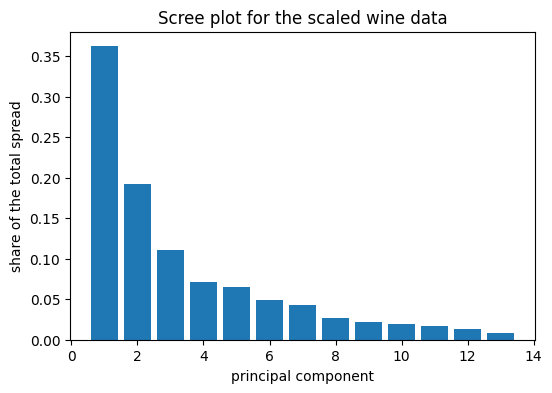

In [11]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
wine_data = load_wine(as_frame=True)
wine = wine_data.data          # the measurements: one row per wine
grower = wine_data.target      # which grower made each wine: 0, 1 or

wine_scaled = StandardScaler().fit_transform(wine)
wine_pca = PCA().fit(wine_scaled)

shares = wine_pca.explained_variance_ratio_
running_total = 0
for number in range(len(shares)):
    running_total += shares[number]
    print("PC" + str(number + 1), "share:", round(shares[number], 3),
          "| running total:", round(running_total, 3))

plt.figure(figsize=(6, 4))
plt.bar(range(1, len(shares) + 1), shares)
plt.xlabel("principal component")
plt.ylabel("share of the total spread")
plt.title("Scree plot for the scaled wine data")
plt.show()

In [10]:
wine_pca

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [15]:
eigenvalues  = wine_pca.explained_variance_    # one number per component, biggest first
eigenvectors = wine_pca.components_            # one ROW per component             # which maths it really used

In [14]:
print(eigenvalues)
print(eigenvectors[0])

[4.73243698 2.51108093 1.45424187 0.92416587 0.85804868 0.64528221
 0.55414147 0.35046627 0.29051203 0.25232001 0.22706428 0.16972374
 0.10396199]
[ 0.1443294  -0.24518758 -0.00205106 -0.23932041  0.14199204  0.39466085
  0.4229343  -0.2985331   0.31342949 -0.0886167   0.29671456  0.37616741
  0.28675223]


In [17]:
import pandas as pd
pc1 = pd.Series(wine_pca.components_[0], index=wine.columns)
pc1

alcohol                         0.144329
malic_acid                     -0.245188
ash                            -0.002051
alcalinity_of_ash              -0.239320
magnesium                       0.141992
total_phenols                   0.394661
flavanoids                      0.422934
nonflavanoid_phenols           -0.298533
proanthocyanins                 0.313429
color_intensity                -0.088617
hue                             0.296715
od280/od315_of_diluted_wines    0.376167
proline                         0.286752
dtype: float64

$$\text{PC1} = 0.144,z_{\text{alcohol}} - 0.245,z_{\text{malic acid}} - 0.002,z_{\text{ash}} + \dots + 0.287,z_{\text{proline}}$$

$$\text{PC1} = w_1 z_1 + w_2 z_2 + \dots + w_{13} z_{13}$$


In [18]:
alcohol = wine["alcohol"]
z_first = (alcohol[0] - alcohol.mean()) / alcohol.std(ddof=0)
print(round(z_first, 3))          # 1.519
print(round(wine_scaled[0, 0], 3))  # same number, from StandardScaler

1.519
1.519


## Slide 62: what PCA is used for

**Visualisation.** Keep only PC1 and PC2, and every wine gets two numbers
instead of 13, so we can finally draw them. The grower is used for the colours
only; PCA never sees it.

**Before running:** will the three growers form separate patches?

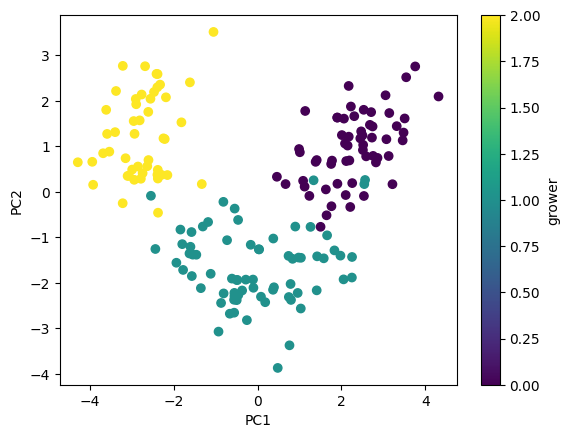

In [20]:
two_numbers = PCA(n_components=2).fit_transform(wine_scaled)
#print(two_numbers)
plt.scatter(two_numbers[:, 0], two_numbers[:, 1], c=grower) #, c=grower
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="grower")
plt.show()

In [ ]:
two_numbers = PCA(n_components=2).fit_transform(wine_scaled)

plt.figure(figsize=(6, 5))
for number in [0, 1, 2]:
    rows = two_numbers[grower == number]
    plt.scatter(rows[:, 0], rows[:, 1], s=15, label="grower " + str(number))
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.title("The wines on their first two principal components")
plt.show()

**Each component is built from all the measurements.** PCA does not pick a few
of the original columns; it builds new ones. Here is how much each of the 13
measurements contributes to PC1.

**Simpler and faster models (slides 48 and 62).** K-NN again, this time on
only two principal components instead of all 13 scaled measurements. As in
Part 3, the scaler and the PCA learn from the training wines only.

**Before running:** with 2 numbers per wine instead of 13, will accuracy fall
a little or a lot?

In [23]:
# choose eps
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

wine_train, wine_test, grower_train, grower_test = train_test_split(
    wine, grower, test_size=0.3, random_state=0, stratify=grower
)
scaler = StandardScaler().fit(wine_train)
train_scaled = scaler.transform(wine_train)
test_scaled = scaler.transform(wine_test)

pca_two = PCA(n_components=3).fit(train_scaled)
train_two = pca_two.transform(train_scaled)
test_two = pca_two.transform(test_scaled)

all_13 = KNeighborsClassifier(n_neighbors=5).fit(train_scaled, grower_train)
only_2 = KNeighborsClassifier(n_neighbors=5).fit(train_two, grower_train)
print("accuracy with all 13 scaled measurements:",
      round(all_13.score(test_scaled, grower_test), 3))
print("accuracy with 3 principal components:    ",
      round(only_2.score(test_two, grower_test), 3))

accuracy with all 13 scaled measurements: 0.963
accuracy with 3 principal components:     0.963


In [24]:
import time


# 1. K-NN on all 13 measurements
start = time.perf_counter()
for repeat in range(100):              # repeat, because one run is too quick to time
    model = KNeighborsClassifier(n_neighbors=5).fit(train_scaled, grower_train)
    model.score(test_scaled, grower_test)
time_knn = (time.perf_counter() - start) / 100

# 2. PCA alone: fit, then turn train and test into 2 components
start = time.perf_counter()
for repeat in range(100):
    pca_two = PCA(n_components=2).fit(train_scaled)
    pca_two.transform(train_scaled)
    pca_two.transform(test_scaled)
time_pca = (time.perf_counter() - start) / 100

print("K-NN on all 13:", round(time_knn * 1000, 3), "milliseconds")
print("PCA alone:     ", round(time_pca * 1000, 3), "milliseconds")

K-NN on all 13: 1.542 milliseconds
PCA alone:      0.262 milliseconds




## Slides 63-64: Labs 6.4 and 6.5

Lab 6.4 uses PCA on the Breast Cancer Wisconsin (Diagnostic) data, including
PCA as a step before a supervised model. Lab 6.5 covers feature selection with
scikit-learn's `sklearn.feature_selection` module on the Pima Indians Diabetes
data.

## Slides 67-68 (appendix): how the methods compare

The appendix grids come from scikit-learn's comparison of clustering methods
on made-up shapes. Here is one row of it: two rings, one inside the other.

**Before running:** which method will separate the inner ring from the outer
ring, K-means or DBSCAN?

In [ ]:
def show_groups(points, groups, title, xlabel="x (made up)", ylabel="y (made up)"):
    """Scatter plot of 2-D points, one colour per group. Run this and move on."""
    plt.figure(figsize=(5, 4))
    plt.scatter(points[:, 0], points[:, 1], c=groups, cmap="viridis", s=12)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

In [ ]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_circles

# Made-up: a small ring inside a big ring.
points, true_group = make_circles(n_samples=500, factor=0.5, noise=0.05, random_state=0)

kmeans_groups = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(points)
show_groups(points, kmeans_groups, "Two rings: K-means")

dbscan_groups = DBSCAN(eps=0.2, min_samples=5).fit_predict(points)
show_groups(points, dbscan_groups, "Two rings: DBSCAN")

K-means draws a straight boundary between two centres, so it slices both rings
in half. DBSCAN follows each ring because the points along a ring are close
together and the gap between rings is empty.

## The module in one table

| method | needs labels? | what you choose | groups it handles well |
|---|---|---|---|
| K-means | no | $K$ | round, similar-sized blobs |
| DBSCAN | no | `eps`, `min_samples` | any shape; also flags noise |
| K-NN | **yes** | $k$, distance, weights | it classifies rather than clusters |
| PCA | no | how many components | not a clustering method: it makes fewer, new features |

When measurements come in different units, scale them before any method
that uses distance or variance. On the wine data that one line was the
biggest single improvement in this notebook, for K-means and for K-NN.

## Slides 65-69

Questions, the appendix title and the end of the deck.

---

*Data Science and AI, Module 6. Wine data: the UCI Wine recognition dataset
(Forina et al.), as bundled with scikit-learn.*